# Prior exponencial para o número de operações: cobertura dos skeletons

**Pergunta:** ao favorecer árvores com mais operações, qual configuração gera maior variedade de skeletons? Comparamos 50.000 árvores com probabilidades fixas de folhas e operadores e 50.000 com essas probabilidades sorteadas para cada árvore. O mesmo número de operações e a mesma seed de AST são usados nas duas condições para cada índice. O sorteio do número de operações e o sorteio das probabilidades têm sequências de seeds separadas.

Um **skeleton** é a lista ordenada de monômios com coeficientes realizados diferentes de zero, sem os valores dos coeficientes. Por exemplo, `1 + x_0(t-6)` marca a presença da constante e do lag 6. Este experimento usa uma série, lags de 1 a 12, de 1 a 6 operações binárias e aceita polinômios até grau 4.

## 1. O que cada método sorteia

A condição fixa usa $p_{\mathrm{parâmetro}}=0{,}40$, $p_{\mathrm{lag}}=0{,}60$ e $p_{\mathrm{soma}}=0{,}65$. Na condição variável, para **cada árvore** sorteamos independentemente
$p_{\mathrm{parâmetro}}\sim\mathcal{U}(0,1)$ e
$p_{\mathrm{soma}}\sim\mathcal{U}(0,1)$; definimos
$p_{\mathrm{lag}}=1-p_{\mathrm{parâmetro}}$ e
$p_{\mathrm{produto}}=1-p_{\mathrm{soma}}$.
Assim, as probabilidades médias de parâmetro e soma passam a 0,50. Dentro de uma árvore, todas as folhas compartilham o mesmo par de probabilidades e todos os operadores compartilham a mesma probabilidade de soma. O número de operadores, os lags admissíveis, os limites dos parâmetros e a exigência de pelo menos um lag permanecem iguais.

Nas duas condicoes, antes de montar a AST, sorteamos tambem o numero K de operacoes binarias pela regra $P(K=k)=e^{0.4(k-1)}/\sum_{j=1}^{6}e^{0.4(j-1)}$, para $k=1,\ldots,6$. O mesmo K e usado nos dois metodos em cada indice. Todos os valores de 1 a 6 tem probabilidade positiva; seis operacoes sao cerca de 7,39 vezes mais provaveis que uma. O coeficiente 0,4 foi escolhido para favorecer arvores maiores sem concentrar todos os sorteios em K=6.

In [1]:
from collections import Counter
from dataclasses import replace
from math import comb, exp, log
from pathlib import Path
from time import perf_counter
import platform
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'pyproject.toml').exists() and (p / 'src/tsfmxai').exists())
sys.path.insert(0, str(ROOT / 'src'))
from tsfmxai.generators import (
    RandomTreeConfig, derive_sample_seed, sample_random_mechanism,
)
from tsfmxai.representations import Lag, canonicalize_polynomial, walk

ROOT_SEED = 20261028
SAMPLE_COUNT = 50_000
CHECKPOINTS = (100, 500, 1_000, 5_000, 10_000, 20_000, 50_000)
MAX_DEGREE = 4
TOP_N = 15
BASE = RandomTreeConfig()
OPERATOR_SLOPE = 0.4
OPERATOR_COUNTS = np.arange(BASE.minimum_operators, BASE.maximum_operators + 1)
OPERATOR_WEIGHTS = np.exp(OPERATOR_SLOPE * (OPERATOR_COUNTS - OPERATOR_COUNTS.min()))
OPERATOR_PROBS = OPERATOR_WEIGHTS / OPERATOR_WEIGHTS.sum()
assert BASE.num_series == 1 and BASE.minimum_lag == 1 and BASE.maximum_lag == 12
assert (BASE.parameter_probability, BASE.lag_probability, BASE.add_probability) == (.4, .6, .65)
LAG_COUNT = BASE.maximum_lag - BASE.minimum_lag + 1
POSSIBLE_MONOMIALS = comb(LAG_COUNT + MAX_DEGREE, MAX_DEGREE)
assert POSSIBLE_MONOMIALS == 1820
print('Base:', BASE)
print('Seed raiz:', ROOT_SEED, '| sorteios por condição:', SAMPLE_COUNT)

Base: RandomTreeConfig(minimum_operators=1, maximum_operators=6, num_series=1, minimum_lag=1, maximum_lag=12, parameter_probability=0.4, lag_probability=0.6, add_probability=0.65, minimum_parameter_magnitude=0.05, maximum_parameter_magnitude=0.9, require_lag=True, coefficient_gate_lags=False)
Seed raiz: 20261028 | sorteios por condição: 50000


**O que foi feito:** definimos uma comparação pareada, o vocabulário e os mesmos limites usados na análise anterior. A seed raiz é registrada e cada índice produz uma seed local estável.

In [2]:
def probabilities_for_index(index):
    probability_seed = np.random.SeedSequence(
        [ROOT_SEED, index, 20261028]
    ).generate_state(1, dtype=np.uint64)[0]
    rng = np.random.default_rng(int(probability_seed))
    p_parameter = float(rng.uniform(0.0, 1.0))
    p_add = float(rng.uniform(0.0, 1.0))
    return p_parameter, 1. - p_parameter, p_add

probability_rows = np.asarray(
    [probabilities_for_index(index) for index in range(SAMPLE_COUNT)]
)
assert np.all((0 < probability_rows) & (probability_rows < 1))
assert np.allclose(probability_rows[:, 0] + probability_rows[:, 1], 1.)
assert probabilities_for_index(8) == probabilities_for_index(8)
probability_df = pd.DataFrame(
    probability_rows, columns=['Parâmetro', 'Lag', 'Soma']
)
display(probability_df.describe(percentiles=[.05, .5, .95]).round(3))

,Parâmetro,Lag,Soma
count,50000.000,50000.000,50000.000
mean,0.502,0.498,0.499
std,0.288,0.288,0.290
min,0.000,0.000,0.000
5%,0.051,0.050,0.049
50%,0.503,0.497,0.499
95%,0.950,0.949,0.950
max,1.000,1.000,1.000


**O que foi feito:** sorteamos um conjunto independente de probabilidades uniformes por árvore. A tabela mostra a dispersão realizada e permite conferir as médias próximas de 0,50.

## 2. Sorteio exponencial das operacoes

A tabela mostra as probabilidades teoricas e as frequencias observadas nos 50.000 sorteios. Cada indice usa uma seed propria, separada das seeds das probabilidades e da AST.

In [3]:
def operator_count_for_index(index):
    operator_seed = np.random.SeedSequence(
        [ROOT_SEED, index, 20261029]
    ).generate_state(1, dtype=np.uint64)[0]
    rng = np.random.default_rng(int(operator_seed))
    return int(rng.choice(OPERATOR_COUNTS, p=OPERATOR_PROBS))

operator_count_rows = np.asarray(
    [operator_count_for_index(index) for index in range(SAMPLE_COUNT)]
)
assert operator_count_for_index(8) == operator_count_for_index(8)
assert set(operator_count_rows) == set(OPERATOR_COUNTS)
operator_df = pd.DataFrame({
    'Operacoes': OPERATOR_COUNTS,
    'Probabilidade teorica (%)': 100 * OPERATOR_PROBS,
    'Arvores sorteadas': np.bincount(operator_count_rows, minlength=7)[1:7],
})
operator_df['Frequencia observada (%)'] = 100 * operator_df['Arvores sorteadas'] / SAMPLE_COUNT
display(operator_df.round(2))


,Operacoes,Probabilidade teorica (%),Arvores sorteadas,Frequencia observada (%)
0,1,4.91,2447,4.89
1,2,7.32,3596,7.19
2,3,10.92,5402,10.80
3,4,16.29,8129,16.26
4,5,24.30,12145,24.29
5,6,36.26,18281,36.56


**O que foi feito:** sorteamos de forma reproduzivel a quantidade de operacoes de cada arvore. A frequencia cresce de 1 ate 6, e a mesma sequencia e usada nos dois metodos.

In [4]:
METHODS = ('Fixa', 'Probabilidades sorteadas')
def new_stats():
    return {
        'supports': Counter(), 'lag_leaves': Counter(),
        'lag_presence': Counter(), 'monomials': {degree: set() for degree in range(5)},
        'degree_tree_count': Counter(), 'accepted': 0, 'degree_rejected': 0,
        'sample_seconds': 0., 'canonical_seconds': 0.,
    }

stats = {method: new_stats() for method in METHODS}
checkpoints = []
for index in range(SAMPLE_COUNT):
    tree_seed = derive_sample_seed(ROOT_SEED, index)
    p_parameter, p_lag, p_add = probability_rows[index]
    operator_count = int(operator_count_rows[index])
    configs = {
        'Fixa': replace(BASE, minimum_operators=operator_count, maximum_operators=operator_count),
        'Probabilidades sorteadas': replace(
            BASE, minimum_operators=operator_count, maximum_operators=operator_count,
            parameter_probability=float(p_parameter),
            lag_probability=float(p_lag), add_probability=float(p_add),
        ),
    }
    for method in METHODS:
        st = stats[method]
        started = perf_counter()
        mechanism = sample_random_mechanism(
            configs[method], seed=tree_seed, sample_index=index,
        )
        st['sample_seconds'] += perf_counter() - started
        for node in walk(mechanism.expression):
            if isinstance(node, Lag):
                st['lag_leaves'][mechanism.binding.lag_values[node.slot]] += 1
        started = perf_counter()
        try:
            normal = canonicalize_polynomial(
                mechanism.expression, mechanism.binding, max_degree=MAX_DEGREE,
            )
        except ValueError as error:
            assert 'degree' in str(error), (method, index, str(error))
            st['degree_rejected'] += 1
        else:
            st['accepted'] += 1
            st['supports'][normal.skeleton] += 1
            degrees, present_lags = set(), set()
            for term in normal.skeleton:
                degree = len(term)
                degrees.add(degree)
                st['monomials'][degree].add(term)
                present_lags.update(lag for _, lag in term)
            st['degree_tree_count'].update(degrees)
            st['lag_presence'].update(present_lags)
        st['canonical_seconds'] += perf_counter() - started
    if index + 1 in CHECKPOINTS:
        for method in METHODS:
            st = stats[method]
            checkpoints.append({
                'Método': method, 'Gerações': index + 1,
                'Convertidas': st['accepted'],
                'Rejeitadas por grau': st['degree_rejected'],
                'Suportes distintos': len(st['supports']),
                'Lags presentes': sum(st['lag_presence'][lag] > 0
                                     for lag in range(1, 13)),
            })

for method in METHODS:
    st = stats[method]
    assert st['accepted'] + st['degree_rejected'] == SAMPLE_COUNT
    assert sum(st['supports'].values()) == st['accepted']
coverage_df = pd.DataFrame(checkpoints)
display(coverage_df)

,Método,Gerações,Convertidas,Rejeitadas por grau,Suportes distintos,Lags presentes
0,Fixa,100,100,0,93,12
1,Probabilidades sorteadas,100,95,5,76,12
2,Fixa,500,494,6,420,12
3,Probabilidades sorteadas,500,469,31,297,12
4,Fixa,1000,993,7,802,12
5,Probabilidades sorteadas,1000,943,57,566,12
6,Fixa,5000,4964,36,3359,12
7,Probabilidades sorteadas,5000,4672,328,2354,12
8,Fixa,10000,9930,70,6110,12
9,Probabilidades sorteadas,10000,9351,649,4272,12


**O que foi feito:** para cada índice, usamos a mesma seed de AST nas duas condições e seeds separadas para sortear as probabilidades. Cada árvore foi expandida e convertida em suporte; rejeições de grau ficaram registradas. A tabela acompanha a diversidade ao longo dos mesmos prefixos de gerações. A quantidade de operacoes foi a mesma por indice nos dois metodos.

In [5]:
def effective_diversity(counts):
    total = sum(counts.values())
    return exp(-sum((count/total) * log(count/total)
                    for count in counts.values()))

summary_rows, factor_rows, lag_rows = [], [], []
for method in METHODS:
    st = stats[method]
    top_fifteen = sum(count for _, count in st['supports'].most_common(TOP_N))
    summary_rows.append({
        'Método': method, 'Convertidas': st['accepted'],
        'Rejeitadas por grau': st['degree_rejected'],
        'Suportes distintos': len(st['supports']),
        'Suportes que aparecem uma vez': sum(
            count == 1 for count in st['supports'].values()),
        'Diversidade efetiva (exp entropia)': effective_diversity(st['supports']),
        'Top 15 entre convertidas (%)': 100 * top_fifteen / st['accepted'],
        'Amostragem (s)': st['sample_seconds'],
        'Canonização (s)': st['canonical_seconds'],
        'Convertidas/s, tempo medido': st['accepted'] / (
            st['sample_seconds'] + st['canonical_seconds']),
    })
    for lag in range(1, LAG_COUNT + 1):
        lag_rows.append({
            'Método': method, 'Lag': lag,
            'Folhas sorteadas': st['lag_leaves'][lag],
            'Convertidas que usam o lag': st['lag_presence'][lag],
            'Convertidas que usam o lag (%)':
                100 * st['lag_presence'][lag] / st['accepted'],
        })
    for degree in range(MAX_DEGREE + 1):
        possible = comb(LAG_COUNT + degree - 1, degree) if degree else 1
        observed = len(st['monomials'][degree])
        factor_rows.append({
            'Método': method, 'Fatores por termo': degree,
            'Monômios possíveis': possible,
            'Monômios observados': observed,
            'Cobertura (%)': 100 * observed / possible,
            'Convertidas com esse grau': st['degree_tree_count'][degree],
        })
summary_df = pd.DataFrame(summary_rows)
factor_df = pd.DataFrame(factor_rows)
lag_df = pd.DataFrame(lag_rows)
display(summary_df.round(3))
display(factor_df.round(2))
display(lag_df.round(2))
assert factor_df.groupby('Método')['Monômios possíveis'].sum().eq(POSSIBLE_MONOMIALS).all()

,Método,Convertidas,Rejeitadas por grau,Suportes distintos,Suportes que aparecem uma vez,Diversidade efetiva (exp entropia),Top 15 entre convertidas (%),Amostragem (s),Canonização (s),"Convertidas/s, tempo medido"
0,Fixa,49704,296,24033,20107,7624.537,10.182,20.358,6.380,1858.965
1,Probabilidades sorteadas,46777,3223,16165,13309,1885.776,27.535,20.673,5.892,1760.870


,Método,Fatores por termo,Monômios possíveis,Monômios observados,Cobertura (%),Convertidas com esse grau
0,Fixa,0,1,1,100.00,27252
1,Fixa,1,12,12,100.00,41912
2,Fixa,2,78,78,100.00,24573
3,Fixa,3,364,364,100.00,8496
4,Fixa,4,1365,1079,79.05,1789
5,Probabilidades sorteadas,0,1,1,100.00,22444
6,Probabilidades sorteadas,1,12,12,100.00,36122
7,Probabilidades sorteadas,2,78,78,100.00,13895
8,Probabilidades sorteadas,3,364,364,100.00,7188
9,Probabilidades sorteadas,4,1365,1235,90.48,3543


,Método,Lag,Folhas sorteadas,Convertidas que usam o lag,Convertidas que usam o lag (%)
0,Fixa,1,13840,12174,24.49
1,Fixa,2,14013,12261,24.67
2,Fixa,3,14067,12302,24.75
3,Fixa,4,13910,12187,24.52
4,Fixa,5,14257,12445,25.04
5,Fixa,6,14054,12329,24.80
6,Fixa,7,14395,12562,25.27
7,Fixa,8,13989,12295,24.74
8,Fixa,9,14236,12449,25.05
9,Fixa,10,13875,12152,24.45


**O que foi feito:** a primeira tabela reúne diversidade, concentração e custo medido. As seguintes mostram a cobertura dos 12 lags e de monômios com zero a quatro fatores. Diversidade efetiva é `exp(entropia)` das frequências dos suportes: ela diminui quando poucos padrões dominam.

In [6]:
def support_formula(support):
    if not support:
        return '0'
    terms = []
    for monomial in support:
        if not monomial:
            terms.append('1')
            continue
        multiplicities = Counter(monomial)
        terms.append(' × '.join(
            f'x_{series}(t-{lag})' + (f'^{power}' if power > 1 else '')
            for (series, lag), power in sorted(multiplicities.items())
        ))
    return ' + '.join(terms)

top_rows = []
for method in METHODS:
    st = stats[method]
    ranked = sorted(st['supports'].items(), key=lambda item: (-item[1], item[0]))
    for rank, (support, count) in enumerate(ranked[:TOP_N], start=1):
        top_rows.append({
            'Método': method, 'Posição': rank,
            'Fórmula do suporte (sem coeficientes)': support_formula(support),
            'Convertidas': count,
            'Frequência entre convertidas (%)': 100 * count / st['accepted'],
        })
top_df = pd.DataFrame(top_rows)
display(top_df.round(3))

,Método,Posição,Fórmula do suporte (sem coeficientes),Convertidas,Frequência entre convertidas (%)
0,Fixa,1,1 + x_0(t-6),429,0.863
1,Fixa,2,1 + x_0(t-2),422,0.849
2,Fixa,3,1 + x_0(t-9),411,0.827
3,Fixa,4,1 + x_0(t-3),404,0.813
4,Fixa,5,1 + x_0(t-5),390,0.785
5,Fixa,6,1 + x_0(t-8),390,0.785
6,Fixa,7,1 + x_0(t-10),390,0.785
7,Fixa,8,1 + x_0(t-4),389,0.783
8,Fixa,9,1 + x_0(t-12),389,0.783
9,Fixa,10,1 + x_0(t-1),383,0.771


**O que foi feito:** listamos as fórmulas dos 15 suportes mais frequentes em cada condição. A contagem considera árvores convertidas; coeficientes diferentes compartilham o mesmo suporte.

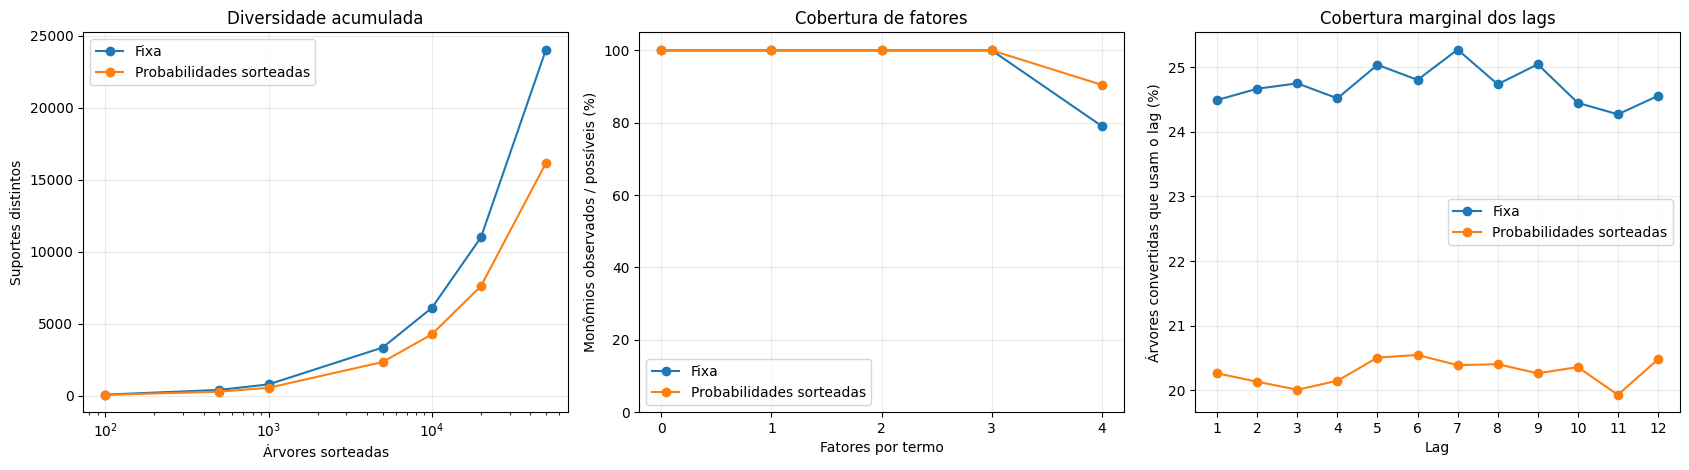

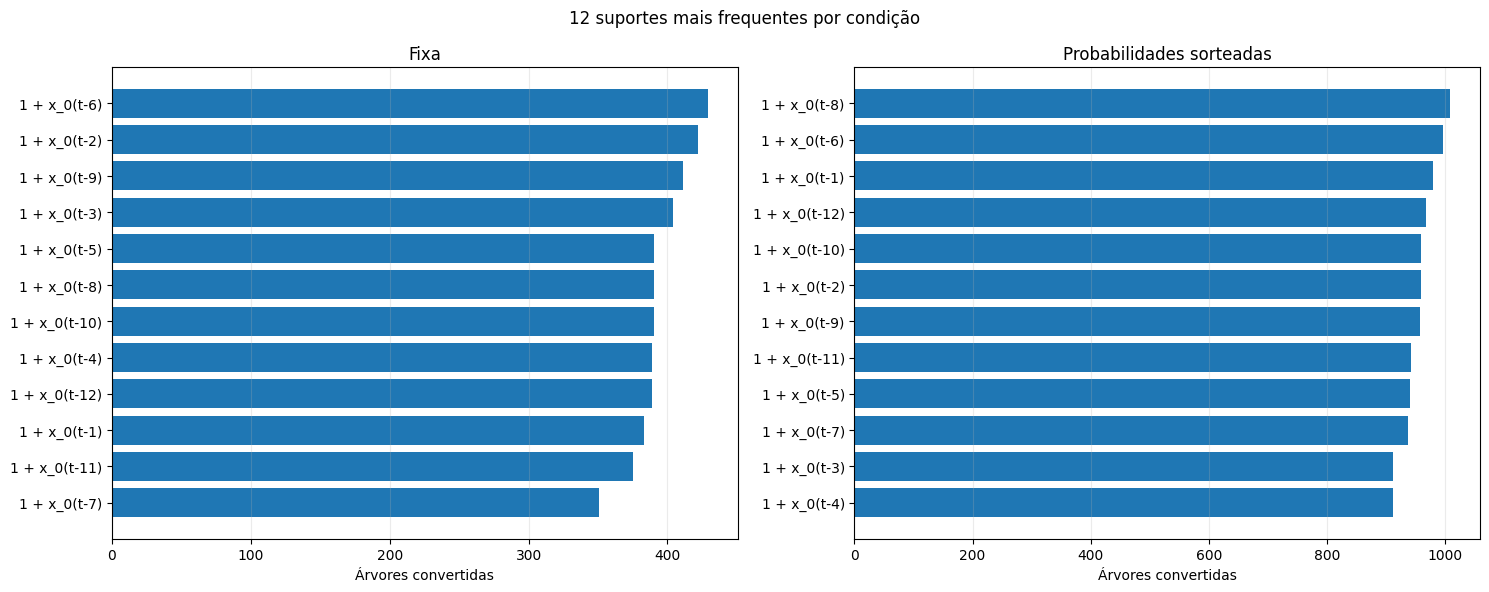

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for method in METHODS:
    part = coverage_df[coverage_df['Método'].eq(method)]
    axes[0].plot(part['Gerações'], part['Suportes distintos'], marker='o', label=method)
axes[0].set(xscale='log', xlabel='Árvores sorteadas', ylabel='Suportes distintos',
            title='Diversidade acumulada')
axes[0].legend()
for method in METHODS:
    part = factor_df[factor_df['Método'].eq(method)]
    axes[1].plot(part['Fatores por termo'], part['Cobertura (%)'], marker='o', label=method)
axes[1].set(xlabel='Fatores por termo', ylabel='Monômios observados / possíveis (%)',
            title='Cobertura de fatores', ylim=(0, 105))
axes[1].set_xticks(range(5))
axes[1].legend()
for method in METHODS:
    part = lag_df[lag_df['Método'].eq(method)]
    axes[2].plot(part['Lag'], part['Convertidas que usam o lag (%)'],
                 marker='o', label=method)
axes[2].set(xlabel='Lag', ylabel='Árvores convertidas que usam o lag (%)',
            title='Cobertura marginal dos lags')
axes[2].set_xticks(range(1, 13))
axes[2].legend()
for ax in axes: ax.grid(alpha=.25)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, method in zip(axes, METHODS):
    part = top_df[top_df['Método'].eq(method)].head(12).iloc[::-1]
    ax.barh(part['Fórmula do suporte (sem coeficientes)'], part['Convertidas'])
    ax.set(xlabel='Árvores convertidas', title=method)
    ax.grid(axis='x', alpha=.25)
fig.suptitle('12 suportes mais frequentes por condição')
fig.tight_layout()
plt.show()

**O que foi feito:** os gráficos comparam descoberta acumulada, cobertura por grau, presença de cada lag e as fórmulas mais frequentes. As escalas e denominadores são iguais entre as condições.

In [8]:
base_row, mixed_row = summary_df.set_index('Método').loc[list(METHODS)].to_dict('records')
delta = mixed_row['Suportes distintos'] - base_row['Suportes distintos']
relative = 100 * delta / base_row['Suportes distintos']
base_degree4 = factor_df.query("Método == 'Fixa' and `Fatores por termo` == 4").iloc[0]
mixed_degree4 = factor_df.query("Método == 'Probabilidades sorteadas' and `Fatores por termo` == 4").iloc[0]
print(f'Diferença em suportes distintos: {delta:+d} ({relative:+.2f}%).')
print('Cobertura de grau 4: %.2f%% -> %.2f%%' %
      (base_degree4['Cobertura (%)'], mixed_degree4['Cobertura (%)']))
print('A comparação mede a prior resultante do sorteio de probabilidades por árvore.')

Diferença em suportes distintos: -7868 (-32.74%).
Cobertura de grau 4: 79.05% -> 90.48%
A comparação mede a prior resultante do sorteio de probabilidades por árvore.


**O que foi feito:** sintetizamos o efeito observado na diversidade e na cobertura dos produtos de quatro fatores, mantendo explícita a configuração que produziu o resultado.

## 3. Escolha para os próximos experimentos

**Configuração escolhida:** probabilidades fixas de 0,40 para parâmetro, 0,60 para lag, 0,65 para soma e 0,35 para produto; número de operações sorteado entre 1 e 6 com pesos proporcionais a `exp(0,4*(K-1))`. A prior de operações é igual nas duas condições da comparação. O gerador monta primeiro uma árvore binária estrita com K operadores e K+1 folhas; cada folha é sorteada como parâmetro ou lag, e cada operador como soma ou produto. Para folhas do tipo lag, a série e o atraso são sorteados depois. Nesta avaliação, `num_series=1`, por isso todos os lags pertencem a `x_0`.

| Sorteio de K | Probabilidades das folhas/operadores | Skeletons distintos | Cobertura dos monômios de grau 4 | Top 15 entre convertidas | Rejeitadas por grau > 4 |
|---|---|---:|---:|---:|---:|
| Uniforme entre 1 e 6 | Fixas | 17.101 | 59,41% | 19,13% | 162 |
| Uniforme entre 1 e 6 | Sorteadas por árvore | 12.141 | 83,59% | 31,47% | 1.843 |
| Exponencial crescente | **Fixas (escolhida)** | **24.033** | 79,05% | **10,18%** | **296** |
| Exponencial crescente | Sorteadas por árvore | 16.165 | **90,48%** | 27,54% | 3.223 |

As duas primeiras linhas vêm do [experimento anterior](../randomized_probabilities/1_randomized_probability_coverage.ipynb); as duas últimas são calculadas neste notebook. Cada linha usa 50.000 árvores e a mesma seed raiz. A configuração escolhida encontrou mais skeletons distintos e distribuiu melhor as amostras entre eles, medida pela menor concentração nos 15 mais frequentes. Ela também elevou a cobertura de monômios de grau 4 de 59,41% para 79,05% em relação à configuração anterior com probabilidades fixas. Sortear as probabilidades por árvore cobriu mais monômios de grau 4, mas repetiu mais os mesmos skeletons e gerou mais polinômios rejeitados pelo teto de grau 4.

**Alcance da conclusão:** cobertura significa padrões observados nesta amostra e nestes limites; o conjunto matematicamente possível de dependências não mudou. A preferência atual é pela diversidade de skeletons. O teste ainda cobre apenas uma série e não mede interações entre séries. A distribuição exponencial aqui é aplicada externamente ao `sample_random_mechanism` ao fixar, para cada chamada, `minimum_operators=maximum_operators=K`; o valor padrão de `RandomTreeConfig()` continua sorteando K uniformemente.

In [9]:
# Registro completo do experimento executado
record = {
    'pergunta': 'Como uma prior exponencial para o numero de operacoes altera a cobertura de suportes sob probabilidades fixas e sorteadas?',
    'hipotese': 'Prior exponencial crescente para K amplia a diversidade de skeletons; comparar probabilidades fixas e uniformes por arvore.',
    'configuracao_completa': {
        'base_config': BASE.__dict__, 'conditions': METHODS,
        'sample_count_per_condition': SAMPLE_COUNT, 'checkpoints': CHECKPOINTS,
        'probability_prior': {
            'parameter': 'Uniform(0, 1)', 'lag': '1 - p_parameter',
            'addition': 'Uniform(0, 1)', 'multiplication': '1 - p_add',
            'draws_per_tree': True, 'max_polynomial_degree': MAX_DEGREE,
        },
        'top_supports_reported': TOP_N,
        'operator_prior': {'counts': OPERATOR_COUNTS.tolist(), 'slope': OPERATOR_SLOPE,
                           'probabilities': OPERATOR_PROBS.tolist(),
                           'same_operator_count_per_index_for_both_methods': True},
    },
    'proveniencia': {
        'notebook': 'experiments/canonicalization/exponential_operator_prior/1_exponential_operator_coverage.ipynb',
        'sampler': 'src/tsfmxai/generators/random_expression.py',
        'canonicalizer': 'src/tsfmxai/representations/canonical_polynomial.py',
        'randomness': 'tree_seed=derive_sample_seed(root_seed,index); probability_seed=SeedSequence([root_seed,index,20261028]); operator_seed=SeedSequence([root_seed,index,20261029])',
        'root_seed': ROOT_SEED, 'sample_indices': [0, SAMPLE_COUNT - 1],
        'python': platform.python_version(), 'numpy': np.__version__,
        'pandas': pd.__version__, 'matplotlib': matplotlib.__version__,
        'hardware': 'CPU', 'external_data': None,
    },
    'metricas': {
        'probability_summary': probability_df.describe(percentiles=[.05,.5,.95]).to_dict(),
        'operator_count_distribution': operator_df.to_dict(orient='records'),
        'selected_method': 'fixed_leaf_and_operator_probabilities_with_exponential_operator_prior',
        'summary': summary_df.to_dict(orient='records'),
        'checkpoints': coverage_df.to_dict(orient='records'),
        'lag_coverage': lag_df.to_dict(orient='records'),
        'factor_coverage': factor_df.to_dict(orient='records'),
        'top_supports': top_df.to_dict(orient='records'),
        'possible_monomials': POSSIBLE_MONOMIALS,
    },
    'escolha_para_experimentos_seguintes': 'Probabilidades fixas de parametro/lag/soma/produto e prior exponencial crescente para K.',
    'resumo_cientifico': (
        f"Com {SAMPLE_COUNT} ASTs por condição, a base produziu {base_row['Suportes distintos']} "
        f"suportes e as probabilidades sorteadas produziram {mixed_row['Suportes distintos']}; "
        f"diferença de {delta:+d} ({relative:+.2f}%). "
        f"O grau 4 cobriu {base_degree4['Cobertura (%)']:.2f}% e "
        f"{mixed_degree4['Cobertura (%)']:.2f}%, respectivamente. "
        'Escolhemos probabilidades fixas com prior exponencial para K pela maior diversidade observada. A cobertura de grau 4 da alternativa com probabilidades sorteadas foi maior. O teste usa uma serie e uma seed raiz.'
    ),
    'reproducao': (
        'A partir da raiz: .venv\\Scripts\\python.exe -m jupyter nbconvert '
        '--to notebook --execute --inplace '
        'experiments/canonicalization/exponential_operator_prior/'
        '1_exponential_operator_coverage.ipynb'
    ),
}
from pprint import pprint
pprint(record, sort_dicts=False)

{'pergunta': 'Como uma prior exponencial para o numero de operacoes altera a '
             'cobertura de suportes sob probabilidades fixas e sorteadas?',
 'hipotese': 'Prior exponencial crescente para K amplia a diversidade de '
             'skeletons; comparar probabilidades fixas e uniformes por arvore.',
 'configuracao_completa': {'base_config': {'minimum_operators': 1,
                                           'maximum_operators': 6,
                                           'num_series': 1,
                                           'minimum_lag': 1,
                                           'maximum_lag': 12,
                                           'parameter_probability': 0.4,
                                           'lag_probability': 0.6,
                                           'add_probability': 0.65,
                                           'minimum_parameter_magnitude': 0.05,
                                           'maximum_parameter_magnitude': 0.9,
     